# Counting challenge - AI solution: YOLO26m-seg + SAHI

**Task:** count the items in each of the 25 images and overlay a mask on every item (accuracy target > 95%).

**Approach**
1. Every photo is cut into **1024 x 1024 tiles** (20% overlap). Each tile was labelled with **polygons** (YOLO-seg format),
   one class, `item` (nuts, screws and bolts are all just "items" - the task asks for a count).
2. A **YOLO26m-seg** instance-segmentation model (COCO-pretrained) is **fine-tuned** on the tiles (Colab T4 GPU).
3. At inference **SAHI** slices each full-resolution photo into 1024 px slices (20% overlap), runs the model on every slice
   and merges duplicate masks from overlapping slices. **Count = number of masks left; overlay = those masks.**
4. Accuracy per photo = `1 - |predicted - true| / true`, averaged over photos (plus exact-match rate), reported separately for
   **validation photos** (never seen in training) and training photos.

**Dataset (not committed to git, see `AI/README.md` for how it was made)**
- Split **by whole photo, never by tile**: 17 photos for training, 8 for validation (31% of the tiles). Neighbouring tiles overlap, so a tile split would leak.
- Training tiles were augmented offline (6 copies per tile: flips, rotations, light brightness/contrast, noise, blur), so the
  built-in Ultralytics augmentation is switched off. Validation tiles are original and unaugmented.

**Files expected in Google Drive** (`MyDrive/`):
```
augmented-correct-dataset-counting-split.zip   train/{images,labels}, val/{images,labels}, data.yaml
CountingChallenge/raw/                         the 25 original photos
CountingChallenge/ground_truth.csv             image,count   (hand-checked true count per photo)
```
Run the cells from top to bottom. Sections 1-7 train the model, sections 8-12 run SAHI on the 25 photos and score it.

## 1. Install and check Ultralytics

In [ ]:
%pip install ultralytics
import ultralytics
ultralytics.checks()

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


## 2. Mount Google Drive and find the dataset zip

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!find /content/drive/MyDrive -name "*.zip" 2>/dev/null

/content/drive/MyDrive/cpp_poc_dataset.zip
/content/drive/MyDrive/flanges_dataset.zip
/content/drive/MyDrive/dimension_dataset_v2.zip
/content/drive/MyDrive/cpp_dataset_final.zip
/content/drive/MyDrive/GMR_DATASET_FINAL.zip
/content/drive/MyDrive/GMR_DATASET.zip
/content/drive/MyDrive/GMR_FEEDBACK_DATASET.zip
/content/drive/MyDrive/pipe_tee_elbow_dataset.zip
/content/drive/MyDrive/futurepipes_superset_dimension.zip
/content/drive/MyDrive/dataset_cpp_v3_final.zip
/content/drive/MyDrive/augmented-correct-dataset-counting-split.zip


## 3. Unzip the dataset
The zip holds `train/` and `val/` (each with `images/` and `labels/`) and a `data.yaml`. Unzipped to `/content/count` on
the Colab disk (fast local storage). The unzip log is long, so it is not shown here.

In [ ]:
!unzip "/content/drive/MyDrive/augmented-correct-dataset-counting-split.zip" -d /content/count

Archive:  /content/drive/MyDrive/augmented-correct-dataset-counting-split.zip
(unzip log trimmed - train/ 1554 tiles, val/ 101 tiles, data.yaml, classes.txt)


## 4. Point `data.yaml` at the unzipped folders
Ultralytics needs absolute paths to the train and val image folders. One class, `item`.

In [ ]:
with open('/content/count/augmented-correct-dataset-counting-split/data.yaml', 'r') as f:
    print(f.read())

train: train/images
val: val/images

nc: 1
names: ['item']



In [ ]:
new_data_yaml = """
train: /content/count/augmented-correct-dataset-counting-split/train/images
val: /content/count/augmented-correct-dataset-counting-split/val/images
nc: 1
names: ['item']
"""

with open('/content/count/augmented-correct-dataset-counting-split/data.yaml', 'w') as f:
    f.write(new_data_yaml)

In [ ]:
with open('/content/count/augmented-correct-dataset-counting-split/data.yaml', 'r') as f:
    print(f.read())


train: /content/count/augmented-correct-dataset-counting-split/train/images
val: /content/count/augmented-correct-dataset-counting-split/val/images
nc: 1
names: ['item']



## 5. Train YOLO26m-seg
- **Model:** `yolo26m-seg.pt`, COCO-pretrained, fine-tuned on one class.
- **`imgsz=1024`:** same size as the tiles, so objects are not shrunk. **`batch=4`** is what fits a T4 at this size.
- **`epochs=100`, `patience=20`:** early stopping ends training once the validation score stops improving.
- **All built-in augmentation is set to 0** (mosaic, flips, rotation, scale, shear, HSV, mixup, ...): the training tiles were
  already augmented offline with labels transformed together with the pixels, and the validation tiles must stay clean.
- **`save_period=10`** keeps a checkpoint every 10 epochs in case Colab disconnects.

Result: training stopped early after 29 epochs (2.1 h). The best epoch was 9 and `best.pt` is that epoch.
Validation of `best.pt` on the 101 val tiles (mask): precision 0.956, recall 0.915, mAP50 0.949, mAP50-95 0.735.

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26m-seg.pt")

model.train(
    data="/content/count/augmented-correct-dataset-counting-split/data.yaml",

    epochs=100,
    imgsz=1024,
    batch=4,
    patience=20,

    # disable built-in augmentation explicitly
    mosaic=0.0,
    fliplr=0.0,
    flipud=0.0,

    degrees=0.0,
    translate=0.0,
    scale=0.0,
    shear=0.0,
    perspective=0.0,

    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.0,

    mixup=0.0,
    cutmix=0.0,
    copy_paste=0.0,
    erasing=0.0,

    name="count_item",

    save_period=10,
    cache=False,

    device=0,
    workers=2
)

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/count/augmented-correct-dataset-counting-split/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.0, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1024, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m-seg.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=count_item-2, nbs=64

## 6. Training curves
Training loss falls steadily, while validation mAP is roughly flat from the first epochs (peak at epoch 9) and validation loss is
noisy: the COCO-pretrained model adapts quickly, and later epochs mostly fit the augmented training tiles. That is why
`best.pt` comes from an early epoch.

In [ ]:
import pandas as pd

df = pd.read_csv("/content/runs/segment/count_item-2/results.csv")
print(df.columns)


Index(['epoch', 'time', 'train/box_loss', 'train/seg_loss', 'train/cls_loss',
       'train/l1_loss', 'train/sem_loss', 'metrics/precision(B)',
       'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)',
       'metrics/precision(M)', 'metrics/recall(M)', 'metrics/mAP50(M)',
       'metrics/mAP50-95(M)', 'val/box_loss', 'val/seg_loss', 'val/cls_loss',
       'val/l1_loss', 'val/sem_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2'],
      dtype='object')


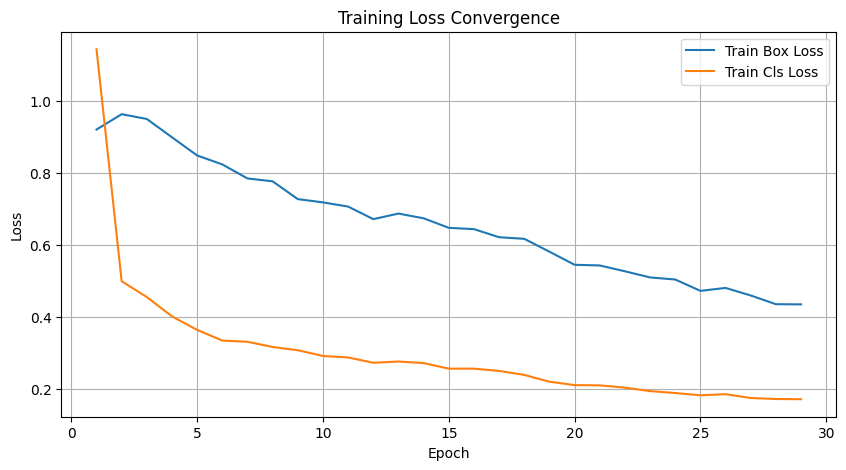

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/runs/segment/count_item-2/results.csv")

plt.figure(figsize=(10,5))
plt.plot(df["epoch"], df["train/box_loss"], label="Train Box Loss")
plt.plot(df["epoch"], df["train/cls_loss"], label="Train Cls Loss")
#plt.plot(df["epoch"], df["train/dfl_loss"], label="Train DFL Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss Convergence")
plt.legend()
plt.grid(True)
plt.show()


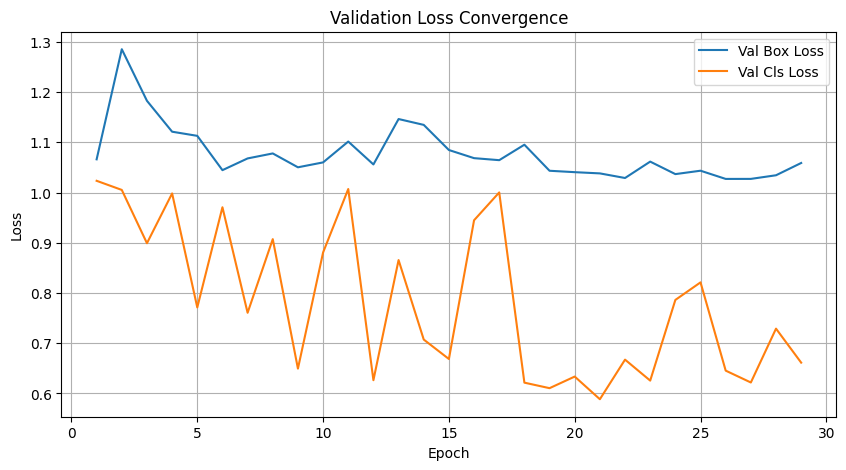

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(df["epoch"], df["val/box_loss"], label="Val Box Loss")
plt.plot(df["epoch"], df["val/cls_loss"], label="Val Cls Loss")
#plt.plot(df["epoch"], df["val/dfl_loss"], label="Val DFL Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Validation Loss Convergence")
plt.legend()
plt.grid(True)
plt.show()


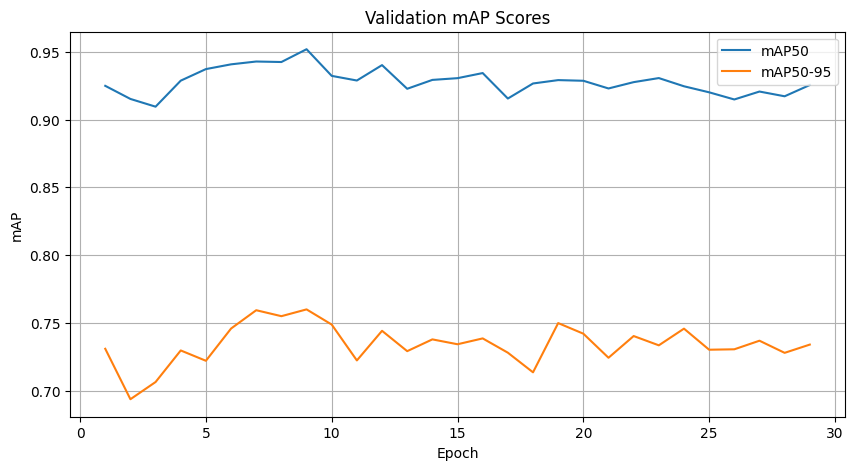

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP50")
plt.plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP50-95")
plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("Validation mAP Scores")
plt.legend()
plt.grid(True)
plt.show()


## 7. Save the best weights
`best.pt` is the checkpoint with the best validation score. Copy it to `count_item_2.pt` and download it (also keep a copy
on Drive). It is **not** committed to git.

In [ ]:
!cp /content/runs/segment/count_item-2/weights/best.pt /content/count_item_2.pt

In [ ]:
from google.colab import files
files.download('/content/count_item_2.pt')

## 8. SAHI inference on the 25 original photos
The tile-level validation score above is only a detection score. The task is **counting on whole photos**, so the model is run on
the full-resolution photos with SAHI:
1. The photo is cut into 1024 x 1024 slices with 20% overlap (the same tiling as in training).
2. The model runs on every slice (`image_size=1024`; without it SAHI would shrink each slice to 640).
3. Detections below a confidence threshold are dropped.
4. **Duplicates from overlapping slices are merged by mask NMS:** highest score first; a mask is dropped if its overlap area is
   more than `match_thr` of the *smaller* mask (IOS). Measuring against the smaller mask also removes a small partial mask lying on
   a full one, which would otherwise count one large screw twice.
5. **Count = number of masks left.** The overlay draws those masks on the full photo.

The slices are run **once** at a low confidence and cached, so trying different confidence / merge thresholds in section 10 is cheap.

In [ ]:
%pip install -q sahi==0.14.0 shapely pandas pillow

In [ ]:
import os, json, csv, shutil, collections
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image, ImageOps, ImageDraw
import torch
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction
from shapely.geometry import Polygon
from shapely.strtree import STRtree

# ---- paths (change ROOT if you keep the files elsewhere) ----
ROOT   = Path(os.environ.get("CC_ROOT", "/content/drive/MyDrive/CountingChallenge"))
RAW    = ROOT / "raw"                       # the 25 original photos (sub-folders are fine)
GT_CSV = ROOT / "ground_truth.csv"          # image,count
OUT    = ROOT / "outputs"; (OUT / "overlays").mkdir(parents=True, exist_ok=True)
WEIGHTS = next((p for p in (Path("/content/runs/segment/count_item-2/weights/best.pt"), Path("/content/count_item_2.pt"),
                            ROOT / "count_item_2.pt", Path("/content/drive/MyDrive/count_item_2.pt")) if p.exists()), None)
assert WEIGHTS, "put count_item_2.pt (the best.pt from training) in the Drive folder"
LIMIT = int(os.environ.get("CC_LIMIT", "0"))       # quick test: only the first N photos

TILE, OVERLAP = 1024, 0.20                        # same as the training tiles
VAL_PHOTOS = {"20240713_193135", "20240713_193659", "20240713_193907", "20240713_194206",
              "20240713_194232", "20240713_194621", "img2", "img4"}        # held out from training
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
det = AutoDetectionModel.from_pretrained(model_type="ultralytics", model_path=str(WEIGHTS),
                                         confidence_threshold=0.10, device=DEVICE, image_size=TILE)
print("weights:", WEIGHTS, "| device:", DEVICE)

def load_rgb(path):
    with Image.open(path) as im:
        return ImageOps.exif_transpose(im).convert("RGB")      # phone photos carry EXIF rotation

PHOTOS = {p.stem: p for p in sorted(RAW.rglob("*")) if p.suffix.lower() in {".jpg", ".jpeg", ".png"}}
if LIMIT: PHOTOS = dict(list(PHOTOS.items())[:LIMIT])
SPLIT = {s: ("val" if s in VAL_PHOTOS else "train") for s in PHOTOS}
print(len(PHOTOS), "photos;", collections.Counter(SPLIT.values()))

RAW_CACHE = {}
def raw_predict(stem):
    # SAHI slices once per photo at a low confidence, no merging yet. Cached, so the grid below is cheap.
    if stem not in RAW_CACHE:
        det.confidence_threshold = 0.10
        r = get_sliced_prediction(load_rgb(PHOTOS[stem]), det, slice_height=TILE, slice_width=TILE,
                                  overlap_height_ratio=OVERLAP, overlap_width_ratio=OVERLAP,
                                  perform_standard_pred=False, postprocess_type="NMS",
                                  postprocess_match_metric="IOS", postprocess_match_threshold=1.01,   # no merge here
                                  postprocess_class_agnostic=True, verbose=0)
        RAW_CACHE[stem] = [(q.score.value, q.mask.segmentation) for q in r.object_prediction_list if q.mask is not None]
    return RAW_CACHE[stem]

def predict_full(stem, conf, match_thr):
    # Keep detections with score >= conf, then greedy mask NMS (highest score first): two masks are the same item when
    # their overlap is more than match_thr of the SMALLER mask (IOS). Returns [(score, [flat polygons in full-image px])].
    polys = []
    for score, segs in raw_predict(stem):
        if score < conf: continue
        ps = [Polygon([(g[i], g[i + 1]) for i in range(0, len(g) - 1, 2)]) for g in segs if len(g) >= 6]
        if not ps: continue
        p = max(ps, key=lambda q: q.area); p = p if p.is_valid else p.buffer(0)
        if not p.is_empty and p.area > 20: polys.append((score, segs, p))
    polys.sort(key=lambda x: -x[0])
    tree = STRtree([p for _, _, p in polys]); dropped, kept = set(), []
    for i, (score, segs, p) in enumerate(polys):
        if i in dropped: continue
        kept.append((score, segs))
        for j in tree.query(p):
            if j > i and j not in dropped and p.intersection(polys[j][2]).area / min(p.area, polys[j][2].area) > match_thr:
                dropped.add(j)
    return kept

def draw_overlay(pil, preds, out_path, max_side=2400):
    scale = min(1.0, max_side / max(pil.size))
    base = pil.resize((int(pil.width * scale), int(pil.height * scale))) if scale < 1 else pil.copy()
    layer = Image.new("RGBA", base.size, (0, 0, 0, 0)); d = ImageDraw.Draw(layer)
    rng = np.random.RandomState(1)
    for _, segs in preds:
        col = tuple(int(c) for c in rng.randint(60, 255, 3))
        for poly in segs:                                     # flat [x1,y1,x2,y2,...] in full-image pixels
            pts = [(poly[i] * scale, poly[i + 1] * scale) for i in range(0, len(poly) - 1, 2)]
            if len(pts) >= 3: d.polygon(pts, fill=col + (110,), outline=col + (255,))
    out = Image.alpha_composite(base.convert("RGBA"), layer).convert("RGB")
    ImageDraw.Draw(out).text((20, 20), f"count = {len(preds)}", fill=(255, 0, 0))
    out.save(out_path, quality=90)

## 9. Ground truth and the accuracy metric
`ground_truth.csv` (`image,count`) has the true count of each full photo (file name without extension). It was built from the
hand-checked tile labels: the tiles were stitched back onto the full photo and an item seen in two overlapping tiles was counted
once. **Accuracy per photo = `1 - |predicted - true| / true`** (clipped at 0); the report gives the mean and the exact-match rate.

In [ ]:
GT = {}
if GT_CSV.exists():
    GT = {str(r["image"]): int(r["count"]) for _, r in pd.read_csv(GT_CSV).dropna(subset=["count"]).iterrows()}
print(len(GT), "ground-truth counts loaded")

def acc(pred, true): return max(0.0, 1 - abs(pred - true) / true)

def evaluate(rows):
    out = [{**r, "true": GT[r["image"]], "acc": acc(r["count"], GT[r["image"]]), "exact": r["count"] == GT[r["image"]]}
           for r in rows if r["image"] in GT]
    return pd.DataFrame(out, columns=["image", "split", "count", "true", "acc", "exact"])

## 10. Choose the confidence and the merge threshold on the validation photos
A small grid (16 settings) scored on the 8 validation photos; the best pair is then fixed for all photos. The validation photos are
also the reported held-out set, so this is a **mild optimistic bias** (stated in `AI/README.md`). The first time this cell runs it
slices every validation photo once (about a minute per photo on a CPU, a few seconds on a T4).

In [ ]:
GRID = [(c, t) for c in (0.25, 0.35, 0.45, 0.55) for t in (0.2, 0.3, 0.4, 0.5)]
scores = []
if GT:
    for conf, thr in GRID:
        rows = [{"image": s, "split": "val", "count": len(predict_full(s, conf, thr))} for s in PHOTOS if SPLIT[s] == "val"]
        df = evaluate(rows)
        if len(df): scores.append((round(df["acc"].mean(), 4), conf, thr))
    scores.sort(reverse=True)
    print("val mean accuracy, conf, merge threshold (best first):"); [print(" ", s) for s in scores[:6]]
CONF, THR = (scores[0][1], scores[0][2]) if scores else (0.35, 0.2)
print("using conf =", CONF, "merge threshold =", THR)

## 11. Run on all 25 photos: overlays, counts and polygons
Writes, to `outputs/` in the Drive folder: one overlay per photo (`overlays/<photo>.jpg`, masks + count), `ai_counts.csv` and
`ai_polygons.json` (the mask outlines in full-image pixels).

In [ ]:
rows, polys = [], {}
for stem in PHOTOS:
    preds = predict_full(stem, CONF, THR)
    draw_overlay(load_rgb(PHOTOS[stem]), preds, OUT / "overlays" / f"{stem}.jpg")
    rows.append({"image": stem, "split": SPLIT[stem], "count": len(preds)})
    polys[stem] = [segs for _, segs in preds]
    print(f"{stem:20s} {SPLIT[stem]:6s} count={len(preds)}")
pd.DataFrame(rows).to_csv(OUT / "ai_counts.csv", index=False)
json.dump(polys, open(OUT / "ai_polygons.json", "w"))

## 12. Accuracy report
`val` = photos never seen in training (**the headline number**). `train` photos were used for training, so their accuracy is optimistic.

In [ ]:
df = evaluate(rows)
if len(df):
    df.to_csv(OUT / "ai_accuracy_per_image.csv", index=False)
    print(df.groupby("split").agg(photos=("acc", "size"), mean_acc=("acc", "mean"), exact_matches=("exact", "sum")).round(4))
    print("\nall photos: mean accuracy %.4f, exact %d of %d" % (df["acc"].mean(), df["exact"].sum(), len(df)))
    print(); print(df[df.split == "val"][["image", "count", "true", "acc"]].round(4).to_string(index=False))
else:
    print("no ground truth yet - counts are in", OUT / "ai_counts.csv")